# A spectrum as the sample: a property read from a curve

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/igbaskin/cmf-qsar/blob/main/docs/tutorials/08_a_spectrum_as_the_sample.ipynb)

In the earlier notebooks the sample is a structure: atoms in space, described by fields. In this
notebook the sample is a **spectrum**, a curve over one axis. The program treats it in the same
way. A spectrum is a field on a line, two spectra are compared by the overlap of the two fields,
and a fitted model gives back a weight over the axis, the **co-spectrum**, as a model of
structures gives back a co-field.

The series continues the seventh notebook. That notebook predicted the Hammett constant of a
substituent from the structure of a substituted benzene. Here the same constant is predicted from
the infrared spectrum of a substituted benzoic acid.

- **The samples** are the infrared spectra of 189 benzoic acids: 94 substituents, each in the
  meta and in the para position, and benzoic acid itself. The spectra were computed with a
  quantum program (ORCA, level r2SCAN-3c) and are stored in `examples/spectra`, so no quantum
  program is needed to run the notebook.
- **The property** is the Hammett constant σ of the substituent at its position: σ<sub>m</sub>
  for a meta acid and σ<sub>p</sub> for a para acid (Hansch, Leo and Taft, Chem. Rev. 1991, 91,
  165). It is a measured number. For most substituents it is the measured change of the acidity
  of this acid against benzoic acid. The calculation of the spectrum does not know it.

Four questions are asked, and each has a lesson that holds for any model of spectra.

1. Does the kernel of the spectra predict the constant?
2. Does the whole spectrum say more than the one band that a chemist would read?
3. Where on the axis does the model find the answer?
4. Does the model read a spectrum that was computed with another method?

Running time: about one minute.

In [1]:
# Run this cell first. On Google Colab it fetches the repository and installs the package;
# on a local checkout it only moves to the repository root, so that the example paths work.
import os, subprocess, sys

if "google.colab" in sys.modules:
    if not os.path.exists("cmf-qsar"):
        subprocess.run(["git", "clone", "-q", "https://github.com/igbaskin/cmf-qsar.git"], check=True)
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "./cmf-qsar", "py3Dmol"], check=True)
    os.chdir("cmf-qsar")
else:
    while not os.path.exists("pyproject.toml") and os.path.dirname(os.getcwd()) != os.getcwd():
        os.chdir("..")
print("working in", os.getcwd())

working in C:\Users\baski\work\claude\cmf


## The data: 189 stick spectra

A quantum program gives a vibrational spectrum as a list of **sticks**: one position (a
wavenumber, in cm⁻¹) and one infrared intensity for every normal mode of the molecule. The class
`Spectrum` of `cmfqsar.spectrum` holds such a list. It also holds a measured curve, which is a
list of intensities on the grid of an instrument.

The constants and the labels are read from the structure file of the same acids. The structures
themselves are not used as a description anywhere in this notebook.

In [2]:
import json
import numpy as np
import matplotlib.pyplot as plt
from rdkit import Chem
from cmfqsar import spectrum as SP

acids = [m for m in Chem.SDMolSupplier("examples/spectra/benzoic_acids_co.sdf", removeHs=False)]
names = [m.GetProp("_Name") for m in acids]
with open("examples/spectra/benzoic_acids_ir.json", encoding="utf-8") as fh:
    sticks = {row["name"]: row for row in json.load(fh)["acids"]}
spectra = [SP.Spectrum(sticks[n]["wavenumbers"], sticks[n]["intensities"], "sticks", "wavenumber", n)
           for n in names]

sigma = np.array([float(m.GetProp("sigma")) for m in acids])
substituent = np.array([m.GetProp("substituent") for m in acids])
position = np.array([m.GetProp("position") for m in acids])
RANGE = (400.0, 4000.0)          # the range of a mid-infrared instrument, in cm-1

lines = [len(s.within(*RANGE)) for s in spectra]
print(len(spectra), "acids:", len(set(substituent)) - 1, "substituents in the meta and in the para position, and benzoic acid")
print("sticks between %d and %d cm-1: %d at the median, %d to %d" % (RANGE + (np.median(lines), min(lines), max(lines))))
print("the Hammett constant runs from %+.2f to %+.2f, standard deviation %.2f" % (sigma.min(), sigma.max(), sigma.std()))

189 acids: 94 substituents in the meta and in the para position, and benzoic acid
sticks between 400 and 4000 cm-1: 43 at the median, 32 to 86
the Hammett constant runs from -0.83 to +1.20, standard deviation 0.33


Three spectra show what the model has to read. Every stick is drawn as a Gaussian with a standard
deviation of 10 cm⁻¹, which is what `SP.broaden` does. The strongest band near 1730 cm⁻¹ is the
stretch of the C=O bond of the carboxyl group. The right panel shows it at a width of 3 cm⁻¹: a
group that donates electrons moves it down, a group that withdraws electrons moves it up. Over
the whole series the band moves by less than 30 cm⁻¹. The left panel also shows bands that only
one acid has, such as the C-H stretches of the two methyl groups near 2900 cm⁻¹.

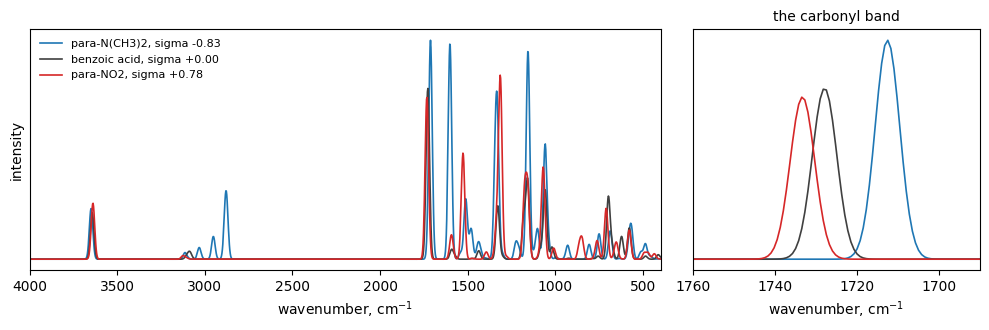

In [3]:
shown = [("para-N(CH3)2", "tab:blue"), ("H", "0.25"), ("para-NO2", "tab:red")]
fig, axes = plt.subplots(1, 2, figsize=(10.0, 3.4), gridspec_kw=dict(width_ratios=(2.2, 1)))
for ax, (lo, hi), width in ((axes[0], RANGE, 10.0), (axes[1], (1690.0, 1760.0), 3.0)):
    grid = SP.Grid(lo, hi, width / 4)
    for name, colour in shown:
        k = names.index(name)
        ax.plot(grid.x, SP.broaden(spectra[k], grid, width), color=colour, lw=1.2,
                label="%s, sigma %+.2f" % ("benzoic acid" if name == "H" else name, sigma[k]))
    ax.set_xlim(hi, lo); ax.set_xlabel("wavenumber, cm$^{-1}$"); ax.set_yticks([])
axes[0].set_ylabel("intensity"); axes[0].legend(frameon=False, fontsize=8)
axes[1].set_title("the carbonyl band", fontsize=10)
plt.tight_layout(); plt.show()

## A spectrum as a field on a line

A molecular field of this program is a sum of Gaussians, one on every atom. A broadened spectrum
is the same object in one dimension: one Gaussian on every stick, with the intensity as its
weight. The kernel of two spectra is the overlap integral of the two broadened curves. For sticks
it has a closed form, a sum over all pairs of sticks, so no grid is needed in principle. The
**cosine form** divides the overlap by the norms of the two spectra. The total intensity then
does not count, and a spectrum compared with itself gives 1.

The standard deviation of the Gaussians, the **width**, is the one setting of this kernel. It
says how far two bands may be apart and still count as the same band. It plays the part that the
attenuation plays for a molecular field.

`SP.kernel` computes the kernel of a set of spectra on a grid that is fine enough for the width.
The first lines below check one value against the closed form.

In [4]:
WIDTH = 5.0
K = SP.kernel(spectra, *RANGE, WIDTH)

a, b = (spectra[names.index(n)].within(*RANGE) for n in ("H", "para-NO2"))
closed_form = SP.stick_overlap(a, b, WIDTH) / np.sqrt(SP.stick_overlap(a, a, WIDTH) * SP.stick_overlap(b, b, WIDTH))
print("benzoic acid against the para-nitro acid: %.4f on the grid, %.4f in closed form"
      % (K[names.index("H"), names.index("para-NO2")], closed_form))

same = (substituent[:, None] == substituent[None, :]) & ~np.eye(len(names), dtype=bool)
other = substituent[:, None] != substituent[None, :]
print("two acids with different substituents: %.2f at the median" % np.median(K[other]))
print("the meta and the para acid of one substituent: %.2f at the median" % np.median(K[same]))
nearest = np.argmax(K - 2.0 * np.eye(len(names)), axis=1)
has_twin = np.array([np.sum(substituent == s) == 2 for s in substituent])
print("the most similar other spectrum is that of the same substituent for %d of %d acids"
      % (np.sum((substituent[nearest] == substituent) & has_twin), has_twin.sum()))

benzoic acid against the para-nitro acid: 0.5233 on the grid, 0.5233 in closed form
two acids with different substituents: 0.50 at the median
the meta and the para acid of one substituent: 0.69 at the median
the most similar other spectrum is that of the same substituent for 38 of 188 acids


The last three lines matter for everything that follows. A spectrum shows the bands of the
substituent itself, so the two acids of one substituent have spectra that are more alike than the
spectra of two other acids. For 38 acids the most similar spectrum of all is that of the other
position; by chance that would happen for one acid. Their constants are related too. If one of the two acids is in the
training set while the other is predicted, the model can recognise the substituent and does not
have to read its effect.

So the folds of the cross-validation hold out **whole substituents**: both acids of a substituent
are predicted by a model that has seen neither. The cross-validation is also run with single acids
held out, to show the difference.

## The model: kernel ridge regression, with the settings chosen inside the folds

The model is the kernel ridge regression of the other notebooks, `krr_fit`, on the kernel of the
spectra. Three settings have to be chosen: the width (2 to 50 cm⁻¹), the **power** of the
intensity (1 keeps the intensity, 0.5 takes its square root, which gives weak bands more weight)
and the ridge parameter. They are chosen on five folds inside every training part, so the acids
that a fold holds out take no part in the choice. The cross-validation has ten folds and is
repeated five times with other folds. q² is the share of the variance of the constant that the
out-of-fold predictions explain.

The next cell holds these steps as six short functions. They work on any kernel matrix, so the
same functions serve the references below.

In [5]:
from collections import Counter
from cmfqsar.model import krr_fit

WIDTHS, POWERS = (2.0, 5.0, 10.0, 20.0, 50.0), (1.0, 0.5)
RIDGES = (1e-6, 1e-5, 1e-4, 1e-3, 1e-2, 1e-1, 1.0, 10.0, 100.0)
FOLDS, INNER_FOLDS, REPEATS = 10, 5, 5


def group_folds(groups, folds, seed):
    """The samples that each fold holds out. All samples of one group go to one fold."""
    labels = np.unique(groups)
    order = np.random.RandomState(seed).permutation(len(labels))
    return [np.flatnonzero(np.isin(groups, labels[order[k::folds]])) for k in range(folds)]


def q2(y, predicted):
    return 1.0 - np.sum((y - predicted) ** 2) / np.sum((y - np.mean(y)) ** 2)


def out_of_fold(K, y, groups, ridge, folds, seed):
    """Predictions of every sample by a model fitted without the fold of that sample."""
    predicted = np.empty(len(y))
    for held_out in group_folds(groups, folds, seed):
        train = np.setdiff1d(np.arange(len(y)), held_out)
        coefficients, bias = krr_fit(K[np.ix_(train, train)], y[train], ridge)
        predicted[held_out] = K[np.ix_(held_out, train)] @ coefficients + bias
    return predicted


def cross_validate(kernels, y, groups):
    """REPEATS x FOLDS folds. `kernels` maps a setting to a kernel matrix; the setting and the
    ridge parameter are chosen on INNER_FOLDS folds inside every training part.
    Returns the predictions, one row per repeat, and how often each setting was chosen."""
    predictions, chosen = [], Counter()
    for seed in range(REPEATS):
        predicted = np.empty(len(y))
        for f, held_out in enumerate(group_folds(groups, FOLDS, seed)):
            train = np.setdiff1d(np.arange(len(y)), held_out)
            best = None
            for setting, K in kernels.items():
                K_train = K[np.ix_(train, train)]
                for ridge in RIDGES:
                    inner = out_of_fold(K_train, y[train], groups[train], ridge, INNER_FOLDS, 1000 * (seed + 1) + f)
                    error = np.sum((y[train] - inner) ** 2)
                    if best is None or error < best[0]:
                        best = (error, setting, ridge)
            _, setting, ridge = best
            K = kernels[setting]
            coefficients, bias = krr_fit(K[np.ix_(train, train)], y[train], ridge)
            predicted[held_out] = K[np.ix_(held_out, train)] @ coefficients + bias
            chosen[setting] += 1
        predictions.append(predicted)
    return np.array(predictions), chosen


def difference(y, a, b, groups, runs=2000, seed=0):
    """q2 of the predictions `a` minus q2 of the predictions `b`, with a 95 % interval from a
    bootstrap over the groups that the folds hold out."""
    error_a, error_b = ((a - y) ** 2).mean(axis=0), ((b - y) ** 2).mean(axis=0)
    members = [np.flatnonzero(groups == g) for g in np.unique(groups)]
    rng, draws = np.random.RandomState(seed), []
    for _ in range(runs):
        rows = np.concatenate([members[i] for i in rng.randint(0, len(members), len(members))])
        draws.append((error_b[rows].sum() - error_a[rows].sum()) / np.sum((y[rows] - y[rows].mean()) ** 2))
    value = (error_b.sum() - error_a.sum()) / np.sum((y - y.mean()) ** 2)
    return "%+.3f [%+.3f, %+.3f]" % (value, np.percentile(draws, 2.5), np.percentile(draws, 97.5))


def mean_q2(y, predictions):
    return float(np.mean([q2(y, p) for p in predictions]))

The kernels of the ten settings, five widths times two powers, take a second. Then the
cross-validation is run twice: with single acids held out and with whole substituents held out.

In [6]:
def spectrum_kernels(some_spectra, lo, hi):
    return {(width, power): SP.kernel(some_spectra, lo, hi, width, power=power)
            for width in WIDTHS for power in POWERS}


def most_chosen(chosen):
    total = sum(chosen.values())
    return "; ".join("%g cm-1, power %g (%d %%)" % (s + (round(100 * n / total),)) for s, n in chosen.most_common(2))


whole = spectrum_kernels(spectra, *RANGE)
each_acid = np.array(names)
designs = {"single acids held out": each_acid, "whole substituents held out": substituent}

predictions = {}
for design, groups in designs.items():
    predictions[design, "spectrum"], chosen = cross_validate(whole, sigma, groups)
    print("%-28s q2 %+.3f   chosen most often: %s"
          % (design, mean_q2(sigma, predictions[design, "spectrum"]), most_chosen(chosen)))

single acids held out        q2 +0.846   chosen most often: 10 cm-1, power 1 (52 %); 5 cm-1, power 1 (46 %)


whole substituents held out  q2 +0.804   chosen most often: 5 cm-1, power 1 (74 %); 10 cm-1, power 1 (16 %)


**Question 1: yes.** With whole substituents held out the kernel of the spectra explains about
80 % of the variance of a measured constant, from a computed spectrum, and nobody told the model
which band to look at.

With single acids held out the number is higher by 0.04. That part is not reading: it is what the
model gains when the other acid of the substituent is in the training set. The number with whole
substituents held out is the one to report, and all numbers below use these folds. The rule is
general: samples that are related, such as two positions of one substituent, several spectra of
one compound or several conformations of one molecule, must be held out together.

## The reference: the one band that a chemist would read

A chemist who is asked for the electronic effect of a substituent on benzoic acid would not read
the whole spectrum. The position of the carbonyl band is known to follow the Hammett constant.
So the reference is one number per acid: the position of that band, which the structure file
holds as `co_stretch`. Two linear regressions on it are fitted on the same folds.

- **One equation** for all acids: σ = a + b · position of the band.
- **Two equations**, one for the meta acids and one for the para acids. This reference is told
  the position of the substituent, which the spectrum model is not told.

In [7]:
band = np.array([float(m.GetProp("co_stretch")) for m in acids])
para = (position == "para").astype(float)


def regression(columns, y, groups):
    """A linear regression on the given columns, fitted and predicted on the same folds."""
    X = np.column_stack([np.ones(len(y)), columns])
    rows = []
    for seed in range(REPEATS):
        predicted = np.empty(len(y))
        for held_out in group_folds(groups, FOLDS, seed):
            train = np.setdiff1d(np.arange(len(y)), held_out)
            predicted[held_out] = X[held_out] @ np.linalg.lstsq(X[train], y[train], rcond=None)[0]
        rows.append(predicted)
    return np.array(rows)


def para_minus_meta(values):
    """The value of the para acid minus the value of the meta acid, for every substituent."""
    pairs = [(np.flatnonzero((substituent == s) & (position == "para")),
              np.flatnonzero((substituent == s) & (position == "meta"))) for s in np.unique(substituent)]
    return np.array([values[p[0]] - values[m[0]] for p, m in pairs if len(p) == 1 and len(m) == 1])


design, groups = "whole substituents held out", substituent
predictions[design, "one band, one equation"] = regression(band, sigma, groups)
predictions[design, "one band, two equations"] = regression(np.column_stack([band, para, band * para]), sigma, groups)

print("correlation of the band position with the constant: %+.3f" % np.corrcoef(band, sigma)[0, 1])
print()
print("%-26s %8s %32s" % ("", "q2", "q2 of para minus meta"))
for model in ("one band, one equation", "one band, two equations", "spectrum"):
    p = predictions[design, model]
    print("%-26s %+8.3f %+32.2f" % (model, mean_q2(sigma, p), q2(para_minus_meta(sigma), para_minus_meta(p.mean(axis=0)))))
print()
for reference in ("one band, one equation", "one band, two equations"):
    print("spectrum minus %-24s %s" % (reference + ":", difference(sigma, predictions[design, "spectrum"], predictions[design, reference], groups)))

correlation of the band position with the constant: +0.866

                                 q2            q2 of para minus meta
one band, one equation       +0.742                            -0.03
one band, two equations      +0.771                            +0.31
spectrum                     +0.804                            +0.38

spectrum minus one band, one equation:  +0.063 [+0.011, +0.127]


spectrum minus one band, two equations: +0.033 [-0.020, +0.095]


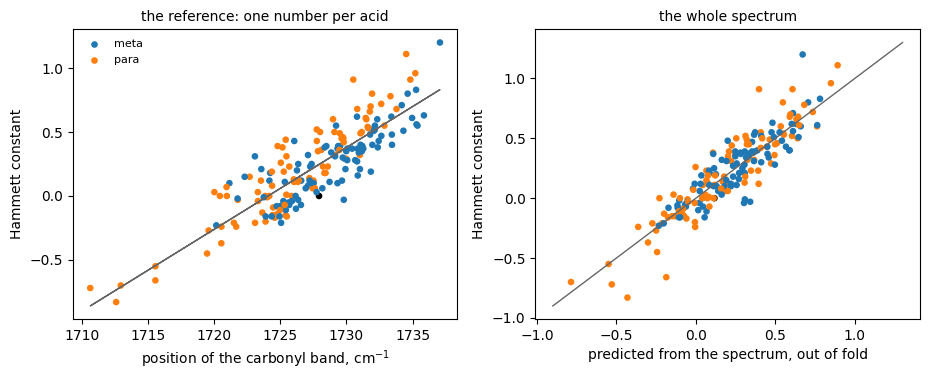

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(9.4, 3.9))
colours = np.where(position == "para", "tab:orange", np.where(position == "meta", "tab:blue", "k"))
axes[0].scatter(band, sigma, c=colours, s=14)
slope, intercept = np.polyfit(band, sigma, 1)
axes[0].plot(band, intercept + slope * band, color="0.4", lw=1)
axes[0].set_xlabel("position of the carbonyl band, cm$^{-1}$"); axes[0].set_ylabel("Hammett constant")
axes[0].set_title("the reference: one number per acid", fontsize=10)
p = predictions[design, "spectrum"].mean(axis=0)
axes[1].scatter(p, sigma, c=colours, s=14)
axes[1].plot([-0.9, 1.3], [-0.9, 1.3], color="0.4", lw=1)
axes[1].set_xlabel("predicted from the spectrum, out of fold"); axes[1].set_ylabel("Hammett constant")
axes[1].set_title("the whole spectrum", fontsize=10)
for label, colour in (("meta", "tab:blue"), ("para", "tab:orange")):
    axes[0].scatter([], [], c=colour, s=14, label=label)
axes[0].legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.show()

**Question 2: a little more, and the interval says how little.** The regression on the one band
reaches a q² of 0.74 with a single number per acid. The whole spectrum is above it by about 0.06,
with an interval that excludes zero by a small margin. Against the two equations, which are told
the position of the substituent, the spectrum is not separated: the interval contains zero.

The second number column asks a harder question: the difference between the para acid and the
meta acid of one substituent. The two acids hold the same atoms. Their constants differ because
the effect of a substituent through the π electrons of the ring, the resonance effect, reaches
the para position and hardly reaches the meta position. One equation on the band does not predict
this difference at all. The spectrum predicts part of it, as the two equations do, and the
spectrum was not told which acid is which.

So a model of whole spectra has to be compared with the reading of the known band before its
score is called a result. Here most of the score belongs to that one band.

## Where the information is: the carbonyl region and the rest

The same model is fitted on two parts of the spectrum: the region of the carbonyl band alone,
1600 to 1850 cm⁻¹, and the spectrum with the sticks of that region taken out.

In [9]:
CARBONYL = (1600.0, 1850.0)


def without(spectrum, lo, hi):
    keep = (spectrum.x < lo) | (spectrum.x > hi)
    return SP.Spectrum(spectrum.x[keep], spectrum.y[keep], spectrum.kind, spectrum.axis, spectrum.name)


parts = {"carbonyl region alone": spectrum_kernels(spectra, *CARBONYL),
         "spectrum without it": spectrum_kernels([without(s, *CARBONYL) for s in spectra], *RANGE)}
for part, kernels in parts.items():
    predictions[design, part], chosen = cross_validate(kernels, sigma, groups)
    print("%-24s q2 %+.3f   chosen most often: %s" % (part, mean_q2(sigma, predictions[design, part]), most_chosen(chosen)))
print()
print("carbonyl region minus one band, one equation:", difference(sigma, predictions[design, "carbonyl region alone"], predictions[design, "one band, one equation"], groups))
print("spectrum without it minus the whole spectrum:", difference(sigma, predictions[design, "spectrum without it"], predictions[design, "spectrum"], groups))

carbonyl region alone    q2 +0.729   chosen most often: 10 cm-1, power 1 (72 %); 5 cm-1, power 1 (26 %)


spectrum without it      q2 +0.662   chosen most often: 2 cm-1, power 0.5 (50 %); 5 cm-1, power 0.5 (20 %)

carbonyl region minus one band, one equation: -0.012 [-0.061, +0.028]
spectrum without it minus the whole spectrum: -0.143 [-0.196, -0.094]


The carbonyl region alone gives what the regression on the band position gives: the kernel reads
the band, and it adds nothing to it there. The spectrum without that region still reaches about
0.66, so the rest of the spectrum holds information about the constant too, and it is clearly
below the whole spectrum. The two parts together are worth more than either.

## A control with a known answer

How exactly does this kernel read the position of a band? A control answers that with a target
whose answer is known. The length of the C=O bond in the optimised structure follows the position
of the carbonyl band almost exactly (Badger's rule). So the position of one stick holds the whole
answer, and a regression on that position is the best possible model.

In [10]:
def bond_length(m):
    c, o = (int(i) for i in m.GetProp("co_stretch_atoms").split())
    xyz = m.GetConformer().GetPositions()
    return 100.0 * float(np.linalg.norm(xyz[c] - xyz[o]))        # in pm


length = np.array([bond_length(m) for m in acids])
print("C=O length: %.2f to %.2f pm; correlation with the band position %+.3f" % (length.min(), length.max(), np.corrcoef(band, length)[0, 1]))
control, chosen = cross_validate(whole, length, groups)
control_band = regression(band, length, groups)
print("the whole spectrum      q2 %+.3f   chosen most often: %s" % (mean_q2(length, control), most_chosen(chosen)))
print("one band, one equation  q2 %+.3f" % mean_q2(length, control_band))
print("spectrum minus the regression:", difference(length, control, control_band, groups))

C=O length: 120.88 to 121.60 pm; correlation with the band position -0.987


the whole spectrum      q2 +0.860   chosen most often: 10 cm-1, power 1 (50 %); 5 cm-1, power 1 (34 %)
one band, one equation  q2 +0.973
spectrum minus the regression: -0.113 [-0.154, -0.082]


The kernel finds the answer, and it finds it less exactly than the regression on the position
does. The reason is in the form of the kernel. A band that moves by a few cm⁻¹ changes the
overlap of two broadened bands only a little, while the regression is given the position as a
number. This is a property of every method that compares spectra by overlap, not a fault of the
fit.

The practical rule: if the answer is the position of one known band, measure that position and
use it. The kernel is for the case where it is not known in advance which bands carry the answer.

## The co-spectrum

A kernel ridge model on the cosine kernel is linear in the normalised broadened spectrum z(x). Its
prediction is a constant plus the integral of w(x) · z(x) over the axis. The weight w(x) is the
**co-spectrum**: positive where intensity raises the predicted constant and negative where it
lowers it. `SP.co_spectrum` computes it from the coefficients of the model, and
`SP.co_spectrum_effect` multiplies it by the standard deviation of the intensity over the set,
because a large weight moves no prediction at a place where all spectra are the same.

The model is fitted on all acids with the setting that the folds chose most often, a width of
5 cm⁻¹ and power 1, and a ridge parameter of 0.1.

In [11]:
RIDGE = 0.1
grid = SP.Grid.for_width(*RANGE, WIDTH)
F = SP.feature_matrix(spectra, grid, WIDTH)              # the broadened spectra, one row each
K = SP.spectrum_kernel(F)                                # the cosine kernel of the rows
coefficients, bias = krr_fit(K, sigma, RIDGE)
w = SP.co_spectrum(F, coefficients)
effect = SP.co_spectrum_effect(F, w)
x = grid.x
Z = F / np.linalg.norm(F, axis=1)[:, None]
print("the co-spectrum gives the prediction back: largest difference %.0e" % np.abs(Z @ w + bias - (K @ coefficients + bias)).max())

# the same for 50 models fitted to the constants in random order
rng = np.random.RandomState(0)
by_chance = [np.abs(SP.co_spectrum_effect(F, SP.co_spectrum(F, krr_fit(K, rng.permutation(sigma), RIDGE)[0]))).max()
             for _ in range(50)]
print("largest effect %.4f at %.0f cm-1; in models on constants in random order %.4f at the mean and %.4f at most"
      % (np.abs(effect).max(), x[np.argmax(np.abs(effect))], np.mean(by_chance), np.max(by_chance)))
print("grid points whose effect is above that largest value: %d of %d" % (np.sum(np.abs(effect) > np.max(by_chance)), len(x)))
for place in SP.strongest_regions(x, effect, n=5, separation=20.0):
    print("   %5.0f cm-1   %+.4f" % (place["x"], place["value"]))

the co-spectrum gives the prediction back: largest difference 5e-15


largest effect 0.0283 at 1736 cm-1; in models on constants in random order 0.0282 at the mean and 0.0453 at most
grid points whose effect is above that largest value: 0 of 1801
    1736 cm-1   +0.0283
    1600 cm-1   -0.0204
    1170 cm-1   +0.0113
    1058 cm-1   -0.0102
    1714 cm-1   -0.0094


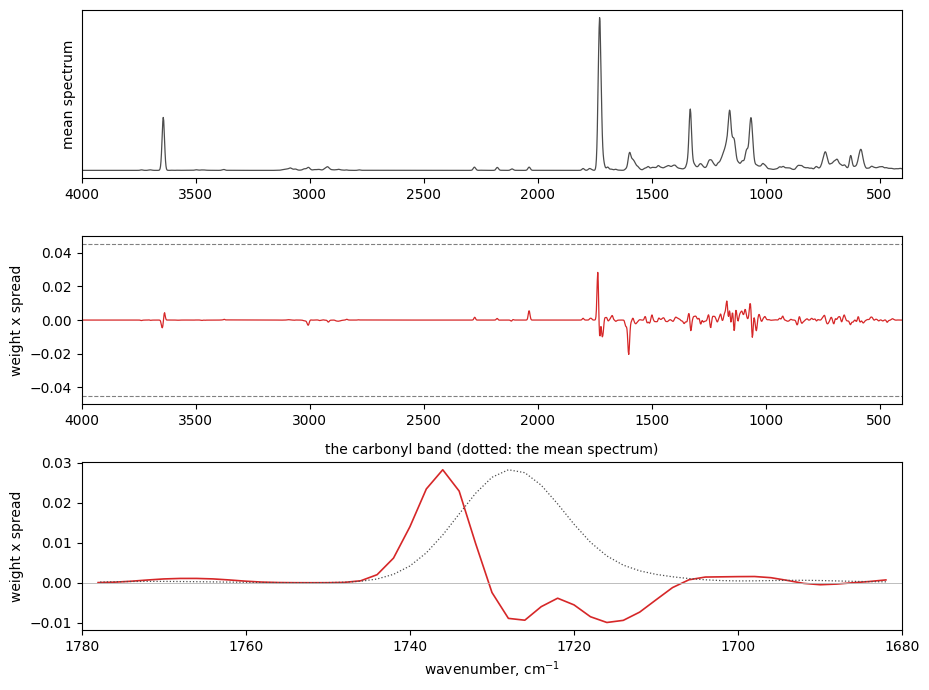

In [12]:
fig, axes = plt.subplots(3, 1, figsize=(9.4, 7.0))
axes[0].plot(x, Z.mean(axis=0), color="0.3", lw=0.9)
axes[0].set_ylabel("mean spectrum"); axes[0].set_yticks([])
axes[1].plot(x, effect, color="tab:red", lw=0.9)
for sign in (-1, 1):
    axes[1].axhline(sign * np.max(by_chance), color="0.5", lw=0.8, ls="--")
axes[1].set_ylabel("weight x spread")
inside = (x > 1680) & (x < 1780)
axes[2].plot(x[inside], effect[inside], color="tab:red", lw=1.2)
mean = Z.mean(axis=0)[inside]
axes[2].plot(x[inside], mean / mean.max() * np.abs(effect[inside]).max(), color="0.3", lw=0.9, ls=":")
axes[2].axhline(0.0, color="0.7", lw=0.6)
axes[2].set_ylabel("weight x spread"); axes[2].set_xlabel("wavenumber, cm$^{-1}$")
axes[2].set_title("the carbonyl band (dotted: the mean spectrum)", fontsize=10)
for ax in axes[:2]:
    ax.set_xlim(RANGE[1], RANGE[0])
axes[2].set_xlim(1780, 1680)
plt.tight_layout(); plt.show()

The largest effect is at 1736 cm⁻¹ with a positive sign, and at 1714 cm⁻¹ the sign is negative.
The bottom panel shows the reason: intensity on the upper side of the carbonyl band raises the
predicted constant and intensity on the lower side lowers it. That is how a linear model of
intensities expresses a band that moves up when the constant rises.

The dashed lines carry the caution. They are the largest effect in fifty models fitted to the
constants in random order, which have nothing to find. No point of the real co-spectrum is above
them. So this co-spectrum **cannot be read point by point**: a single peak of it is no larger
than a peak that chance gives. The reason is that there are 1801 grid points and 189 acids.

It can be read **by region**. The cell below fits the model without the substituent of an acid,
computes for that acid what each region adds to its prediction (the sum of weight times intensity
inside the region), and correlates these sums over all acids with the constant. The same is done
for constants in random order.

In [13]:
REGIONS = ((3450.0, 3800.0, "O-H stretch"), (2800.0, 3200.0, "C-H stretch"), (1650.0, 1800.0, "C=O stretch"),
           (1550.0, 1650.0, "ring stretch"), (1000.0, 1550.0, "C-O stretch, O-H bend, ring modes"),
           (400.0, 1000.0, "out-of-plane bends, ring deformations"))


def region_sums(y):
    """What each region adds to the prediction of an acid, from a model fitted without the
    substituent of that acid."""
    sums = np.zeros((len(y), len(REGIONS)))
    for held_out in group_folds(substituent, FOLDS, 0):
        train = np.setdiff1d(np.arange(len(y)), held_out)
        w_fold = Z[train].T @ krr_fit(K[np.ix_(train, train)], y[train], RIDGE)[0]
        for k, (lo, hi, _) in enumerate(REGIONS):
            inside = (x >= lo) & (x < hi)
            sums[held_out, k] = Z[held_out][:, inside] @ w_fold[inside]
    return sums


def correlations(y):
    sums = region_sums(y)
    return np.array([np.corrcoef(sums[:, k], y)[0, 1] for k in range(len(REGIONS))])


real = correlations(sigma)
chance = np.array([correlations(rng.permutation(sigma)) for _ in range(50)])
print("%-40s %14s %12s %22s" % ("region", "cm-1", "correlation", "largest by chance"))
for (lo, hi, label), r, c in zip(REGIONS, real, chance.max(axis=0)):
    print("%-40s %6.0f to %4.0f %+12.2f %+22.2f" % (label, lo, hi, r, c))

region                                             cm-1  correlation      largest by chance
O-H stretch                                3450 to 3800        +0.82                  +0.17
C-H stretch                                2800 to 3200        +0.44                  +0.21
C=O stretch                                1650 to 1800        +0.79                  +0.13
ring stretch                               1550 to 1650        +0.67                  +0.21
C-O stretch, O-H bend, ring modes          1000 to 1550        +0.55                  +0.16
out-of-plane bends, ring deformations       400 to 1000        +0.20                  +0.26


**Question 3.** Five of the six regions add something to a prediction that follows the constant
far above what chance gives. The carbonyl stretch is one of them, as expected. The stretch of the
O-H bond carries as much, and that is the bond which an acid breaks; the model was not told
either of them. The region below 1000 cm⁻¹ is not above chance in this run.

This is the answer to the second question from another side. The carbonyl band holds most of the
information, the same information is also in other bands, and for that reason the whole spectrum
gains only a little over the one band.

## A spectrum from another method

A model of spectra will be used on spectra that it has not seen. The folder holds the spectra of
the same 189 acids from two other calculations: B97-3c, a quantum method of similar cost, and
GFN2-xTB, a much faster semi-empirical method. They stand here for a second instrument. The model
is fitted on the r2SCAN-3c spectra without the substituent of an acid, and it then predicts that
acid from each of its three spectra. `SP.kernel` with `others=` gives the kernel between new
spectra and the training spectra.

In [14]:
def read_spectra(path):
    with open(path, encoding="utf-8") as fh:
        rows = {row["name"]: row for row in json.load(fh)["acids"]}
    return [SP.Spectrum(rows[n]["wavenumbers"], rows[n]["intensities"], "sticks", "wavenumber", n) for n in names]


K_train = SP.kernel(spectra, *RANGE, WIDTH)
print("%-36s %8s %14s" % ("the spectrum that is read", "q2", "mean error"))
for label, path in (("r2SCAN-3c (the training method)", None),
                    ("B97-3c", "examples/spectra/benzoic_acids_ir_b97-3c.json"),
                    ("GFN2-xTB", "examples/spectra/benzoic_acids_ir_xtb.json")):
    K_new = K_train if path is None else SP.kernel(spectra, *RANGE, WIDTH, others=read_spectra(path))
    predicted = np.empty(len(sigma))
    for held_out in group_folds(substituent, FOLDS, 0):
        train = np.setdiff1d(np.arange(len(sigma)), held_out)
        coefficients, bias = krr_fit(K_train[np.ix_(train, train)], sigma[train], RIDGE)
        predicted[held_out] = K_new[np.ix_(held_out, train)] @ coefficients + bias
    print("%-36s %+8.3f %+14.3f" % (label, q2(sigma, predicted), np.mean(predicted - sigma)))

the spectrum that is read                  q2     mean error
r2SCAN-3c (the training method)        +0.825         -0.001
B97-3c                                 +0.588         -0.045


GFN2-xTB                               +0.009         +0.113


**Question 4: no, not without more work.** Read on the B97-3c spectra the model loses more than a
quarter of its q², and read on the GFN2-xTB spectra it predicts nothing. (The first row is 0.83
and not 0.80 because the width and the ridge parameter are fixed in this cell and not chosen
inside the folds.) Nothing about the acids changed.
What changed is where each method puts its bands and how strong it makes them, and the model
learned the bands of one method.

The same will happen between a computed and a measured spectrum, and between two instruments. A
model of spectra has to be tested on spectra of the kind that it will be given. The manual has
three sections on this: what to do with two instruments, how a measured spectrum compares with
other measured spectra, and how it compares with a library of computed spectra.

## What to take from this notebook

- A spectrum is a sample like a structure. `SP.Spectrum`, `SP.kernel` and `krr_fit` are enough
  for a model, and `SP.co_spectrum` gives the weight over the axis.
- Hold out related samples together. Here the two acids of a substituent raise the q² by 0.04
  when they are separated.
- Compare with the reading of the one known band. Here it reaches 0.74 with one number, and the
  whole spectrum gains about 0.06 over it.
- Check the method on a target with a known answer. An overlap kernel reads the position of a
  band less exactly than a regression on that position.
- Read a co-spectrum by region, and compare with models on targets in random order. Its single
  points were not above chance here.
- A model reads the spectra of the method or the instrument that it was trained on.

The functions for spectra are a Python module; the `cmf` command has no mode for them yet.

Where to read further in the manual: *A spectrum as a one-dimensional field: the kernel and the
co-spectrum* has the equations and the full measurement of this series with the structural
descriptions beside the spectrum, *The spectrum as the bridge* asks which acid fits a given
spectrum, *Mixtures and quantification* treats the spectrum of a mixture, and *Two instruments*
treats a model that is fitted on one instrument and used on another.